# Probability and Sampling Theory: applied to the OASIS-1 data

**Plan for today**

1. **Probability**
   - what is probability? relative frequency, law of large numbers
   - dependent vs. independent events, addition and multiplication rule
   - Bayesian probability, base rates and percentage increases
   - probability distributions: binomial, Poisson, normal
   - z-standardization
2. **Sampling theory**
   - interpretation of sampled z-values
   - choosing your sample, standard error, confidence intervals

Data: `oasis_cross-sectional.csv` (Marcus et al., 2007). Place it in the same folder as this notebook.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb, factorial, exp
from scipy import stats

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
rng = np.random.default_rng(42)   # fixed seed: simulations give the same result every time

## 0. The data

As before, we keep **one row per subject** (the first session, `MR1`): 416 participants.

For the dementia examples we need the participants who received a **Clinical Dementia Rating (CDR)**. Only 235 of the 416 participants were rated (mostly older ones), so we collect them in a second table, `rated`. We call a participant **demented** if `CDR > 0`.

> **Caution:** OASIS is *not* a random sample of the population. We use it as a "small world" to illustrate the concepts, so probabilities computed here describe *this dataset*, not the real prevalence of dementia.

In [3]:
raw = pd.read_csv("oasis_cross-sectional.csv")
df = raw[raw["ID"].str.endswith("MR1")].copy()          # one row per subject
rated = df[df["CDR"].notna()].copy()                    # participants with a dementia rating

print("participants:", len(df), "| with a CDR rating:", len(rated))

participants: 416 | with a CDR rating: 235


Moving forward, we will mainly work with a variant of the dataset that solely consists of the MR1 samples. Therefore, it makes sense to save a version that has these rows dropped. This can be done by:

In [4]:
df.to_csv('oasis_cross-sectional_MR1.csv')

---
# 1. Probability

## 1.1 What is probability?

**Inferential statistics** draws conclusions from a *sample* about the underlying *population*. The result is always a **probability**, never a definite answer!

Probability measures how likely an event is. It lies between 0 and 1 (or 0% and 100%):

- **1**: the event always happens
- **0**: the event never happens
- **0.5**: the event happens as often as it does not happen (chance)

Three ways to think about it:

1. **Intuitive:** a "gut feeling" (it rained today, so it will probably rain tomorrow)
2. **Long-term average:** flip a coin many times, it shows heads about half of the time
3. **Mathematical:** number of favored outcomes divided by number of possible outcomes

In the **OASIS** dataset, we can ask:  what is the probability that a randomly chosen participant is a woman? Favorable outcomes divided by possible outcomes:

In [5]:
n_women = (df["M/F"] == "F").sum()
print(f"p(female) = {n_women}/{len(df)} = {n_women / len(df):.3f}")

p(female) = 256/416 = 0.615


## 1.2 Relative frequency

In the example above we used the **relative frequency** as a measure for probability: the ratio of the number of times an event occurs to the total number of trials.

$$\text{relative frequency} = \frac{\text{number of times the event occurs}}{\text{total number of trials}}$$

We can use it as an estimate of the probability **if the event is random and the number of trials is large**.  Let's consider the relative frequency of dementia among the rated participants:

In [6]:
demented = rated["CDR"] > 0
print(f"{demented.sum()} demented out of {len(rated)} rated participants")
print(f"relative frequency of dementia = {demented.mean():.3f}")

100 demented out of 235 rated participants
relative frequency of dementia = 0.426


## 1.3 Law of large numbers

For a random event with a fixed probability $p$, the relative frequency will come close to $p$ with an increasing number of trials $N$.

Below, five runs of drawing random OASIS participants (our "population" has a share of women of 0.615). The running relative frequency fluctuates strongly at first and then settles down.

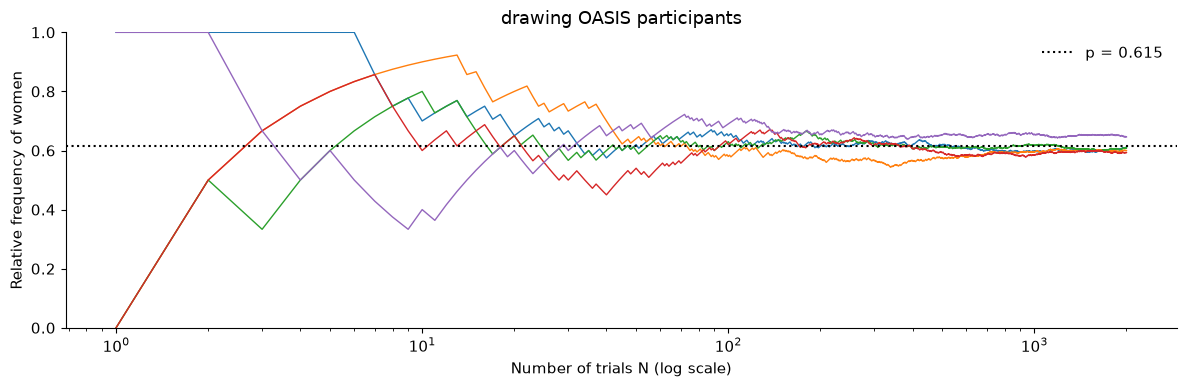

In [7]:
N = 2000
trials = np.arange(1, N + 1)
is_female = (df["M/F"] == "F").to_numpy()
p_female = is_female.mean()

fig, ax = plt.subplots(1, 1, figsize=(12, 4))

for _ in range(5):
    draws = rng.choice(is_female, size=N, replace=True)
    ax.plot(trials, np.cumsum(draws) / trials, lw=1)
ax.axhline(p_female, color="black", ls=":", label=f"p = {p_female:.3f}")
ax.set_title("drawing OASIS participants")
ax.set_ylabel("Relative frequency of women")

ax.set_xscale("log")
ax.set_xlabel("Number of trials N (log scale)")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 1.4 Dependent vs. independent probability

**Dependent (conditional) probability:** the probability of $A$ *given* that $B$ is present:

$$p(A|B) = \frac{p(A \cap B)}{p(B)}$$

**Independent probability:** two events are *stochastically independent* if the occurrence of $A$ is not influenced by the occurrence of $B$.

In the **OASIS** dataset, we can define three events among the rated participants:

- $A$: the participant is demented (`CDR > 0`)
- $B$: the participant is 70 years or older
- $F$: the participant is a woman

In [8]:
A = rated["CDR"] > 0
B = rated["Age"] >= 70
F = rated["M/F"] == "F"

def p(event):
    return event.mean()          # relative frequency of an event (a True/False column)

print(f"p(A) = {p(A):.3f}    p(B) = {p(B):.3f}    p(A and B) = {p(A & B):.3f}")
print()
print(f"p(A | B) = p(A and B) / p(B) = {p(A & B) / p(B):.3f}")
print(f"p(B | A) = p(A and B) / p(A) = {p(A & B) / p(A):.3f}")

p(A) = 0.426    p(B) = 0.672    p(A and B) = 0.362

p(A | B) = p(A and B) / p(B) = 0.538
p(B | A) = p(A and B) / p(A) = 0.850


Note that $p(A|B)$ and $p(B|A)$ are **not the same**: most demented participants are old, but not every old participant is demented.

Are the events independent? If they were, $p(A \cap B)$ would equal $p(A) \cdot p(B)$:

In [9]:
pd.DataFrame({
    "p(X and Y)":   [p(A & B), p(A & F)],
    "p(X) * p(Y)":  [p(A) * p(B), p(A) * p(F)],
}, index=["A: demented, B: age >= 70", "A: demented, F: woman"]).round(3)

,p(X and Y),p(X) * p(Y)
"A: demented, B: age >= 70",0.362,0.286
"A: demented, F: woman",0.251,0.282


In [10]:
print(f"p(demented | woman) = {p(A[F]):.3f}")
print(f"p(demented | man)   = {p(A[~F]):.3f}")

p(demented | woman) = 0.378
p(demented | man)   = 0.519


In this dataset, dementia and age are strongly dependent; dementia and sex are also dependent (the conditional probabilities differ), although less strongly. (These are statements about *this sample*, not about the population.)

## 1.5 Addition and multiplication rule

**Addition rule:** the probability that $A$ **or** $B$ occurs.

- disjoint events (never occur together): $p(A \cup B) = p(A) + p(B)$
- events that can occur together: $p(A \cup B) = p(A) + p(B) - p(A \cap B)$

**Multiplication rule:** the probability that $A$ **and** $B$ occur.

- independent events: $p(A \cap B) = p(A) \cdot p(B)$
- dependent events: $p(A \cap B) = p(A|B) \cdot p(B) = p(B|A) \cdot p(A)$

We check every rule on our data. In each row, the left and right side must agree:

In [11]:
cdr0 = rated["CDR"] == 0          # disjoint: nobody has both ratings
cdr05 = rated["CDR"] == 0.5

rows = [
    ("addition, disjoint: p(CDR 0 or CDR 0.5)",    p(cdr0 | cdr05),         p(cdr0) + p(cdr05)),
    ("addition, not disjoint: p(A or B)",          p(A | B),                p(A) + p(B) - p(A & B)),
    ("multiplication, dependent: p(A|B) * p(B)",   p(A & B),                A[B].mean() * p(B)),
    ("multiplication, dependent: p(B|A) * p(A)",   p(A & B),                B[A].mean() * p(A)),
]
pd.DataFrame(rows, columns=["rule", "left side", "right side"]).set_index("rule").round(4)

,left side,right side
rule,,
"addition, disjoint: p(CDR 0 or CDR 0.5)",0.8723,0.8723
"addition, not disjoint: p(A or B)",0.7362,0.7362
"multiplication, dependent: p(A|B) * p(B)",0.3617,0.3617
"multiplication, dependent: p(B|A) * p(A)",0.3617,0.3617


## 1.6 Bayesian probability

Bayes' theorem relates the two dependent probabilities $p(A|B)$ and $p(B|A)$:

$$p(A|B) = \frac{p(A) \cdot p(B|A)}{p(B)}$$

**Example from the slides: Covid test.** Sensitivity (positive test if infected) 99%, false alarms (positive test if not infected) 5%, probability of having Covid 0.1%. How likely is it that we have Covid if the test is positive?

To compute $p(\text{pos.})$ we use both rules: a positive test is *either* (infected **and** positive) *or* (not infected **and** positive):

$$p(C|\text{pos.}) = \frac{p(C) \cdot p(\text{pos.}|C)}{p(\text{pos.}|C)\,p(C) + p(\text{pos.}|\sim C)\,p(\sim C)}$$

In [12]:
def posterior(prior, sensitivity, false_alarm):
    p_pos = sensitivity * prior + false_alarm * (1 - prior)      # addition + multiplication rule
    return sensitivity * prior / p_pos

prior, sensitivity, false_alarm = 0.001, 0.99, 0.05
p_pos = sensitivity * prior + false_alarm * (1 - prior)

print(f"p(positive test)       = 0.99 * 0.001 + 0.05 * 0.999 = {p_pos:.4f}")
print(f"p(Covid | positive)    = 0.99 * 0.001 / {p_pos:.4f}  = {posterior(prior, sensitivity, false_alarm):.3f}")

p(positive test)       = 0.99 * 0.001 + 0.05 * 0.999 = 0.0509
p(Covid | positive)    = 0.99 * 0.001 / 0.0509  = 0.019


Even after a positive test, the probability is only about 1.9%: the disease is so rare that most positive tests are false alarms.

**Bayesian updating:** use the calculated probability (the *posterior*) as the *prior* in the next calculation. A second positive test (assuming the tests are independent, as on the slide). The slide rounds the first posterior to 0.019 and gets 27.7%; carrying the unrounded value through gives slightly more (28.2%). Every further positive test raises the probability considerably:

In [13]:
# as on the slide: the first posterior, rounded to 0.019, is the prior of the second calculation
print(f"second positive test, prior 0.019: p(Covid) = {posterior(0.019, 0.99, 0.05):.3f}")
print()

# the same, carrying the unrounded posterior through several tests
belief = 0.001
for test in [1, 2, 3]:
    belief = posterior(belief, 0.99, 0.05)
    print(f"after positive test {test}: p(Covid) = {belief:.3f}")

second positive test, prior 0.019: p(Covid) = 0.277

after positive test 1: p(Covid) = 0.019
after positive test 2: p(Covid) = 0.282
after positive test 3: p(Covid) = 0.886


### OASIS: a screening test for dementia

The same logic applies to a screening test. We use the `MMSE` score as a "test" for dementia ($A$): a participant tests **positive** if `MMSE <= 26`. For the participants with both ratings and scores, we estimate from the data:

- **sensitivity:** $p(\text{positive} | \text{demented})$
- **false alarm rate:** $p(\text{positive} | \text{not demented})$
- **prior (base rate):** $p(\text{demented})$

Bayes' theorem should reproduce what we get by simply counting, $p(\text{demented}|\text{positive})$:

In [14]:
tested = rated[rated["MMSE"].notna()]
dem = tested["CDR"] > 0
pos = tested["MMSE"] <= 26

sensitivity = pos[dem].mean()
false_alarm = pos[~dem].mean()
base_rate = dem.mean()

print(f"n = {len(tested)}")
print(f"sensitivity           p(pos | demented)     = {sensitivity:.3f}")
print(f"false alarm rate      p(pos | not demented) = {false_alarm:.3f}")
print(f"base rate             p(demented)           = {base_rate:.3f}")
print()
print(f"p(demented | pos), counting:       {dem[pos].mean():.3f}")
print(f"p(demented | pos), Bayes' theorem: {posterior(base_rate, sensitivity, false_alarm):.3f}")

n = 235
sensitivity           p(pos | demented)     = 0.600
false alarm rate      p(pos | not demented) = 0.052
base rate             p(demented)           = 0.426

p(demented | pos), counting:       0.896
p(demented | pos), Bayes' theorem: 0.896


Both ways agree. But in OASIS, dementia is very common (about 43% of the rated participants). In a population where it is rarer, the **same test** is much less informative:

In [15]:
rates = [base_rate, 0.10, 0.05, 0.01]
pd.DataFrame({
    "base rate p(demented)": rates,
    "p(demented | positive test)": [posterior(r, sensitivity, false_alarm) for r in rates],
}, index=["OASIS", "10%", "5%", "1%"]).round(3)

,base rate p(demented),p(demented | positive test)
OASIS,0.426,0.896
10%,0.100,0.562
5%,0.050,0.379
1%,0.010,0.105


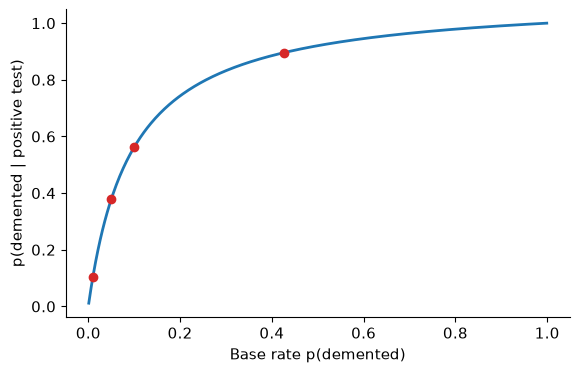

In [16]:
r = np.linspace(0.001, 0.999, 400)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(r, posterior(r, sensitivity, false_alarm), lw=2)
ax.scatter(rates, [posterior(x, sensitivity, false_alarm) for x in rates], color="tab:red", zorder=3)
ax.set_xlabel("Base rate p(demented)")
ax.set_ylabel("p(demented | positive test)")
plt.show()

## 1.7 Base rates and percentage increases

Always consider the **base rate** when talking about percentage increases.

In the **OASIS** dataset, the share of demented participants among the rated ones is higher for older participants. How we describe the difference depends on the base rate (the share among the younger):

In [17]:
rows = []
for cut in [70, 75, 80]:
    old   = A[rated["Age"] >= cut].mean()
    young = A[rated["Age"] <  cut].mean()
    rows.append({
        "split": f"age >= {cut}",
        "base rate (younger)": young,
        "older": old,
        "relative increase": f"{100 * (old / young - 1):+.0f}%",
        "percentage points": f"{100 * (old - young):+.1f}",
    })
pd.DataFrame(rows).set_index("split").round(3)

,base rate (younger),older,relative increase,percentage points
split,,,,
age >= 70,0.195,0.538,+176%,+34.3
age >= 75,0.312,0.561,+79%,+24.8
age >= 80,0.394,0.493,+25%,+10.0


Depending on where we split, the same data give "176% more" or "25% more": the relative increase changes dramatically with the base rate, while the difference in percentage points shows the absolute gap directly. Reporting **both the base rate and the difference in percentage points** avoids misunderstandings.

## 1.8 Probability distributions

A **probability distribution** tells us how likely every potential value of a variable is.

- **discrete** distributions are for discrete / categorical variables (or for categories within a continuous distribution, i.e. a histogram): there is a probability for each value
- **continuous** distributions are for continuous variables: there are only probabilities for *ranges* of values, and the probability is the **area under the curve**

In the **OASIS** dataset, the dementia rating `CDR` is a **discrete** variable with four values. Each has a probability, and all probabilities add up to 1.

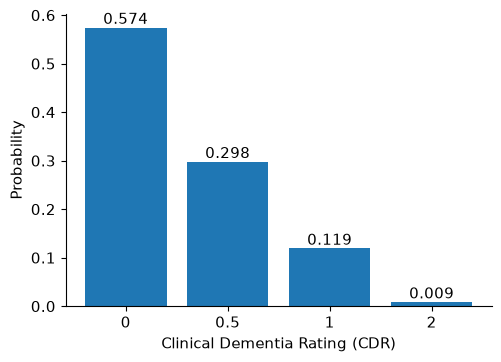

sum of all probabilities: 1.0


In [18]:
cdr_p = rated["CDR"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
bars = ax.bar([f"{c:g}" for c in cdr_p.index], cdr_p.values)
ax.bar_label(bars, fmt="%.3f")
ax.set_xlabel("Clinical Dementia Rating (CDR)")
ax.set_ylabel("Probability")
plt.show()

print("sum of all probabilities:", cdr_p.sum())

In the **OASIS** dataset, the estimated total intracranial volume (`eTIV`) is a **continuous** variable that can take any value in a range. If we sort it into bins of width 100 mm³, the histogram is a *discrete* distribution (left: one probability per bin, bars add up to 1). For the *continuous* distribution (right), we scale the histogram so that the **total area is 1** (a density) and compare it with a normal curve with the same mean and SD. The probability of a range, here 1400 to 1600 mm³, is the area under the curve in that range.

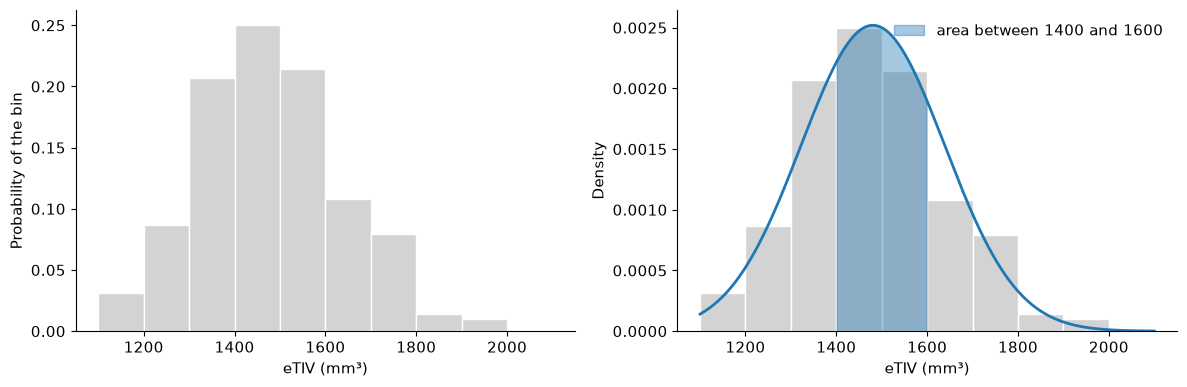

p(1400 <= eTIV <= 1600): counting participants = 0.464
p(1400 <= eTIV <= 1600): area under the normal curve = 0.469


In [19]:
x = df["eTIV"]
mu, s = x.mean(), x.std()
bins = np.arange(1100, 2101, 100)
grid = np.linspace(1100, 2100, 400)
lo, hi = 1400, 1600

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(x, bins=bins, weights=np.ones(len(x)) / len(x), color="lightgray", edgecolor="white")
axes[0].set_ylabel("Probability of the bin")

axes[1].hist(x, bins=bins, density=True, color="lightgray", edgecolor="white")
axes[1].plot(grid, stats.norm.pdf(grid, mu, s), color="tab:blue", lw=2)
mask = (grid >= lo) & (grid <= hi)
axes[1].fill_between(grid[mask], stats.norm.pdf(grid[mask], mu, s), color="tab:blue", alpha=0.4,
                     label=f"area between {lo} and {hi}")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=False, loc="upper right")

for ax in axes:
    ax.set_xlabel("eTIV (mm³)")
plt.tight_layout()
plt.show()

print(f"p({lo} <= eTIV <= {hi}): counting participants = {((x >= lo) & (x <= hi)).mean():.3f}")
print(f"p({lo} <= eTIV <= {hi}): area under the normal curve = {stats.norm.cdf(hi, mu, s) - stats.norm.cdf(lo, mu, s):.3f}")

## 1.9 Binomial distribution

The probability of $k$ successes in $n$ trials, with a base probability $p$ for a success. It is for **discrete** variables with a **fixed number of trials**.

$$p(k|n,p) = \binom{n}{k}\, p^k (1-p)^{n-k} \qquad\qquad \binom{n}{k} = \frac{n!}{k!\,(n-k)!}$$

In the **OASIS** dataset, we draw **10 random participants** with replacement (putting back) and count the women among them. With $p = 0.615$ the number of women should follow a binomial distribution. We repeat the experiment 20,000 times and compare the relative frequencies with the binomial probabilities.

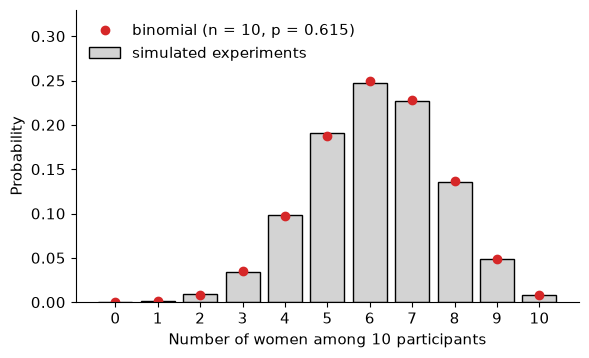

mean number of women: simulated 6.14, n * p = 6.15


In [20]:
n = 10
n_experiments = 20_000
women = rng.choice(is_female, size=(n_experiments, n)).sum(axis=1)

k = np.arange(0, n + 1)
observed = np.bincount(women, minlength=n + 1) / n_experiments
expected = stats.binom.pmf(k, n, p_female)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(k, observed, color="lightgray", edgecolor="black", label="simulated experiments")
ax.plot(k, expected, "o", color="tab:red", label=f"binomial (n = 10, p = {p_female:.3f})")
ax.set_xticks(k)
ax.set_xlabel("Number of women among 10 participants")
ax.set_ylabel("Probability")
ax.set_ylim(0, 0.33)
ax.legend(frameon=False, loc="upper left")
plt.show()

print(f"mean number of women: simulated {women.mean():.2f}, n * p = {n * p_female:.2f}")

## 1.10 Poisson distribution

The probability of $k$ events if the *average* number of events in an interval is $\lambda$. It is for **discrete** variables in a **fixed interval**.

$$p(k|\lambda) = \frac{\exp(-\lambda)\,\lambda^k}{k!}$$

**Example from the slides:** I get four emails a day ($\lambda = 4$). How likely are different numbers of emails tomorrow?

formula and scipy agree: True


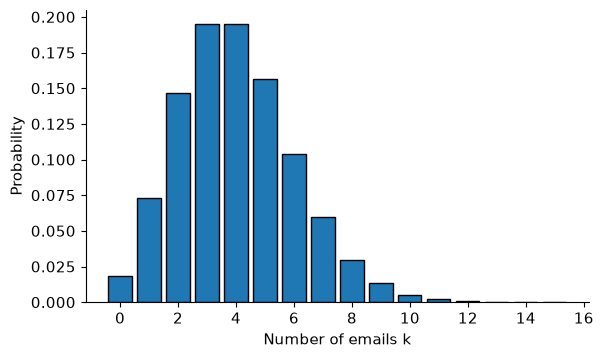

p(no email at all) = 0.018
p(8 or more)       = 0.051


In [21]:
lam = 4
k = np.arange(0, 16)
by_formula = np.array([exp(-lam) * lam**kk / factorial(kk) for kk in k])
print("formula and scipy agree:", np.allclose(by_formula, stats.poisson.pmf(k, lam)))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(k, by_formula, edgecolor="black")
ax.set_xlabel("Number of emails k")
ax.set_ylabel("Probability")
plt.show()

print(f"p(no email at all) = {by_formula[0]:.3f}")
print(f"p(8 or more)       = {1 - by_formula[:8].sum():.3f}")

## 1.11 Normal distribution

The normal distribution is for **continuous variables** whose values spread **symmetrically** around the mean.

- it usually results if a variable is influenced by many different, random, independent factors
- there are infinitely many normal distributions: they all have the same bell shape and differ only in **mean** and **standard deviation**. Mean and SD are all we need to describe the population.
- a normal distribution with $\mu = 0$ and $\sigma = 1$ is the **standard normal distribution**

All parametric tests we will discuss (t-test, ANOVA) **assume normally distributed data**.

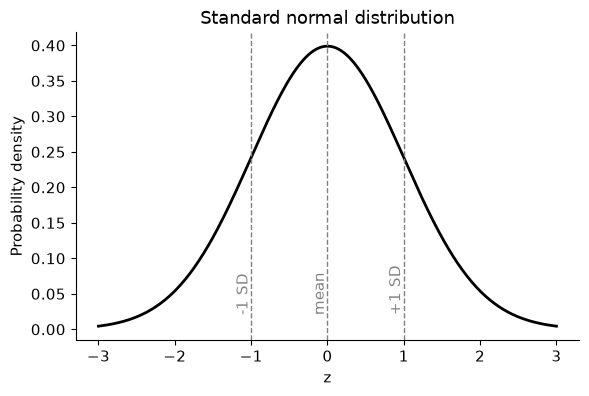

In [22]:
z = np.linspace(-3, 3, 400)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(z, stats.norm.pdf(z), color="black", lw=2)
for value, name in [(-1, "-1 SD"), (0, "mean"), (1, "+1 SD")]:
    ax.axvline(value, color="gray", ls="--", lw=1)
    ax.text(value, 0.02, name, rotation=90, ha="right", va="bottom", color="gray")
ax.set_title("Standard normal distribution")
ax.set_xlabel("z")
ax.set_ylabel("Probability density")
plt.show()

**Do our data look normal?** Histograms of four OASIS columns, each with the normal curve that has the same mean and SD:

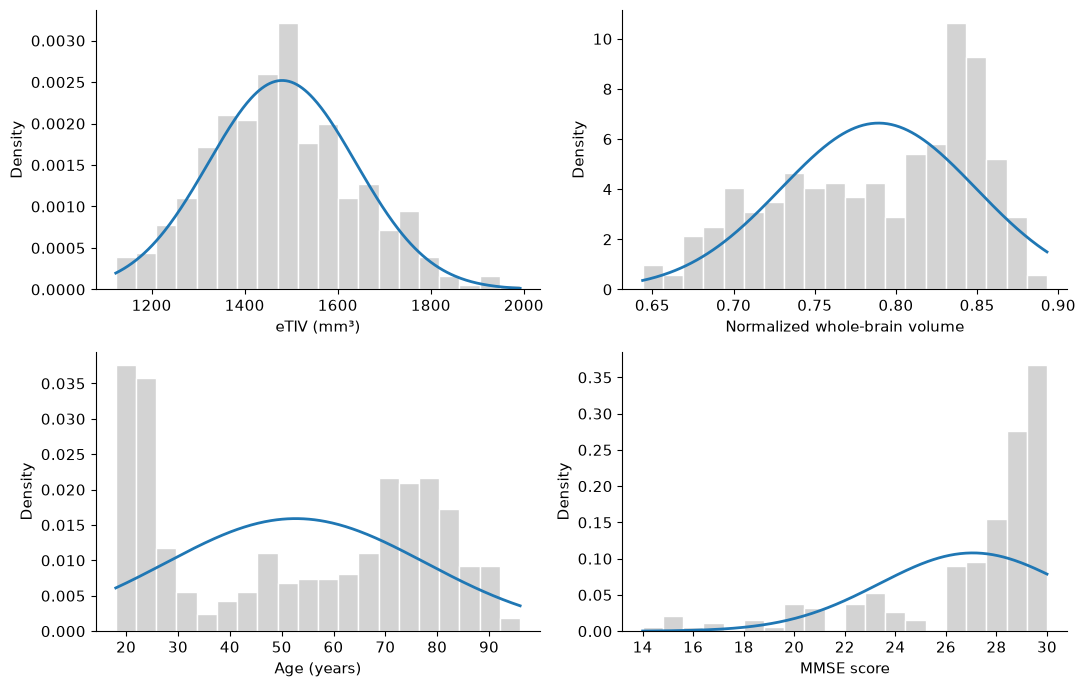

In [23]:
cols = [("eTIV", "eTIV (mm³)"), ("nWBV", "Normalized whole-brain volume"),
        ("Age", "Age (years)"), ("MMSE", "MMSE score")]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, label) in zip(axes.ravel(), cols):
    x = df[col].dropna()
    ax.hist(x, bins=20, density=True, color="lightgray", edgecolor="white")
    grid = np.linspace(x.min(), x.max(), 300)
    ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), color="tab:blue", lw=2)
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

For a normal distribution, 68.3% of the values lie within ±1 SD of the mean and 95.4% within ±2 SD. How close are our columns?

In [24]:
rows = []
for col, _ in cols:
    x = df[col].dropna()
    rows.append({
        "column": col,
        "within 1 SD": (np.abs(x - x.mean()) < x.std()).mean(),
        "within 2 SD": (np.abs(x - x.mean()) < 2 * x.std()).mean(),
    })
rows.append({"column": "normal distribution",
             "within 1 SD": stats.norm.cdf(1) - stats.norm.cdf(-1),
             "within 2 SD": stats.norm.cdf(2) - stats.norm.cdf(-2)})
pd.DataFrame(rows).set_index("column").round(3)

,within 1 SD,within 2 SD
column,,
eTIV,0.675,0.959
nWBV,0.632,0.978
Age,0.476,1.000
MMSE,0.821,0.949
normal distribution,0.683,0.954


`eTIV` is close to normal. `nWBV` is somewhat left-skewed, `MMSE` has a ceiling effect, and `Age` consists of two clusters: these are the "paranormal distributions" for which a normal-based calculation can be misleading.


### Checking normality with a Q-Q plot

A histogram with a normal curve on top is a first look, but it depends on the number of bins and on our eye. A **Q-Q plot** (quantile-quantile plot) is a sharper tool. It compares every observed value with the value we would **expect if the data were normally distributed**:

1. sort the data
2. for each value, compute the share of the data at or below it (using its rank)
3. look up which z-value belongs to this share in the standard normal distribution (the norm table from the next sections, `stats.norm.ppf`)
4. plot the expected z-value (x-axis) against the observed value (y-axis)

If the data are normal, **the points fall on a straight line**. We draw the line that a perfectly normal variable with the same mean and SD would follow. For `eTIV`, step by step:

   observed eTIV  share  expected z
0           1123  0.001      -3.035
1           1131  0.004      -2.687
2           1147  0.006      -2.512
3           1149  0.008      -2.390


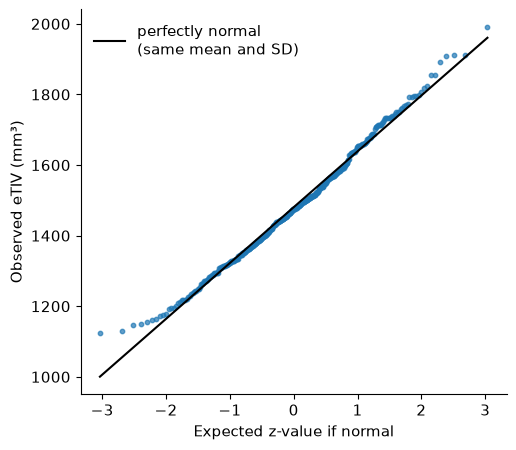

In [25]:
x = df["eTIV"].dropna().to_numpy()
n = len(x)

observed = np.sort(x)                                   # 1. sort the data
prob = (np.arange(1, n + 1) - 0.5) / n                  # 2. share of the data up to each rank
expected_z = stats.norm.ppf(prob)                       # 3. z-value a normal distribution has at that share

print(pd.DataFrame({"observed eTIV": observed, "share": prob, "expected z": expected_z}).head(4).round(3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(expected_z, observed, s=10, alpha=0.7)       # 4. plot
ax.plot(expected_z, x.mean() + x.std() * expected_z, color="black", lw=1.5,
        label="perfectly normal\n(same mean and SD)")
ax.set_xlabel("Expected z-value if normal")
ax.set_ylabel("Observed eTIV (mm³)")
ax.legend(frameon=False)
plt.show()

The points follow the line closely: `eTIV` is close to normal. We wrap the steps in a function and look at all four columns:

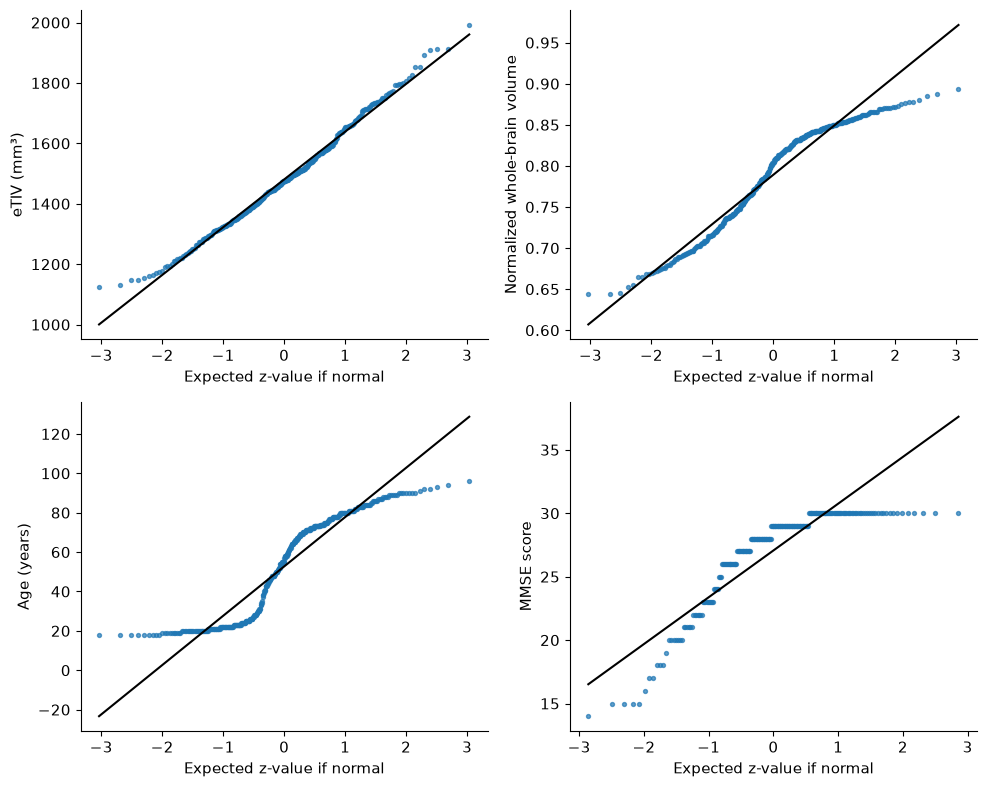

In [26]:
def qq_plot(ax, x, ylabel):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    z = stats.norm.ppf((np.arange(1, len(x) + 1) - 0.5) / len(x))
    ax.scatter(z, np.sort(x), s=8, alpha=0.7)
    ax.plot(z, x.mean() + x.std() * z, color="black", lw=1.5)
    ax.set_xlabel("Expected z-value if normal")
    ax.set_ylabel(ylabel)

qq_cols = [("eTIV", "eTIV (mm³)"), ("nWBV", "Normalized whole-brain volume"),
           ("Age", "Age (years)"), ("MMSE", "MMSE score")]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (col, label) in zip(axes.ravel(), qq_cols):
    qq_plot(ax, df[col], label)
plt.tight_layout()
plt.show()

How to read the plots above:

- **`eTIV`:** the points stay close to the line, with only small deviations at the extreme ends. Close to normal.
- **`nWBV`:** an S-shape. The highest values lie far *below* the line: the data stop at about 0.9, while a normal distribution with this mean and SD would produce larger values. The distribution is cut off at the top and flatter than normal (this is also the left-skewed shape we saw in the histogram).
- **`Age`:** a strong S-shape, steep in the middle and with long flat stretches at both ends. Many participants are bunched at young and at old ages, with few in between (the two clusters). A normal distribution with this mean and SD would even predict negative ages.
- **`MMSE`:** a staircase (the scores are whole numbers) with a plateau at the top (many participants share the maximum score of 30, a *ceiling effect*) and low scores far below the line (a long tail towards low scores).

In general:

- both ends **bend away to the same side** (a banana shape): skewed distribution
- **S-shape**, with the ends flattening out: lighter tails than normal (a flatter or bounded distribution)
- **reversed S**, with the ends shooting off the line: heavier tails (more extreme values than normal)
- **steps and plateaus**: many identical values (discrete or capped data)

Even truly normal data never form a perfect line, especially in small samples. To calibrate our eye, here are four Q-Q plots of samples that *are* normal, each with 50 values:

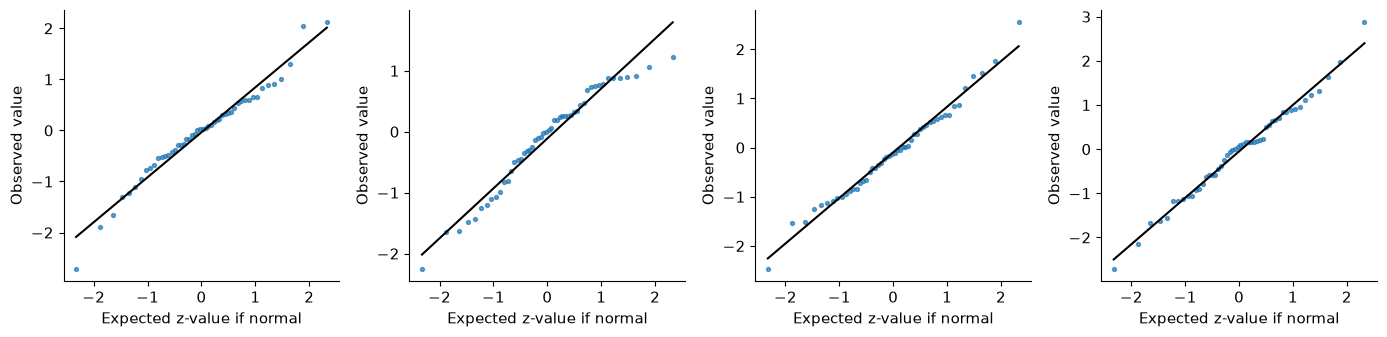

In [27]:
rng_qq = np.random.default_rng(1)      # separate generator: does not change the random numbers used elsewhere

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax in axes:
    qq_plot(ax, rng_qq.normal(size=50), "Observed value")
plt.tight_layout()
plt.show()

Some wiggle, especially at the ends, is normal. The deviations in `nWBV`, `Age` and `MMSE` are far larger and *systematic* (a clear curve, a plateau, a gap).

## 1.12 z-standardization

We can transform every normal distribution into a standard normal distribution:

$$x_{new} = z(x) = \frac{x_{old} - \mu}{\sigma}$$

The result tells us how many standard deviations a value is above (positive) or below (negative) the mean. Standardized values are easy to interpret, because their probabilities can be found in norm tables.

In the **OASIS** dataset, we z-standardize `eTIV` with its sample mean and standard deviation. The mean becomes 0 and the SD becomes 1, but the **shape of the distribution does not change**.

z(eTIV): mean = -0.000, SD = 1.000
same as scipy.stats.zscore: True


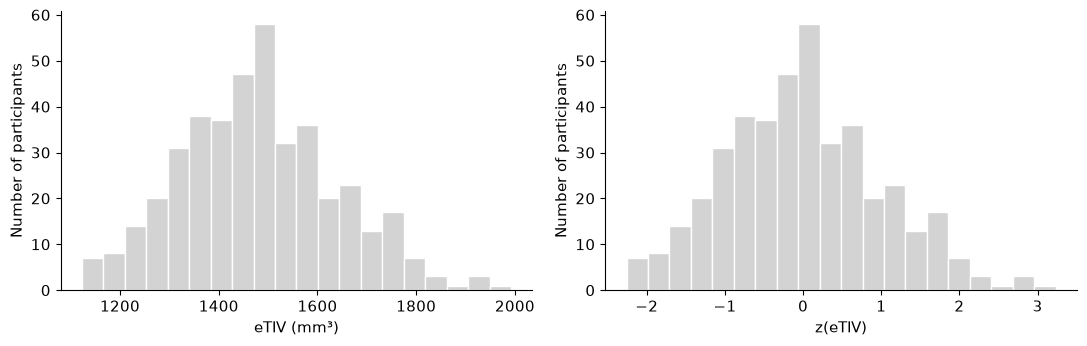

In [28]:
z_etiv = (df["eTIV"] - df["eTIV"].mean()) / df["eTIV"].std()

print(f"z(eTIV): mean = {z_etiv.mean():.3f}, SD = {z_etiv.std():.3f}")
print("same as scipy.stats.zscore:", np.allclose(z_etiv, stats.zscore(df["eTIV"], ddof=1)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["eTIV"], bins=20, color="lightgray", edgecolor="white")
axes[0].set_xlabel("eTIV (mm³)")
axes[1].hist(z_etiv, bins=20, color="lightgray", edgecolor="white")
axes[1].set_xlabel("z(eTIV)")
for ax in axes:
    ax.set_ylabel("Number of participants")
plt.tight_layout()
plt.show()

z-scores have no unit, so values from different variables become comparable. The first five participants, on three different scales:

In [29]:
zs = pd.DataFrame({
    "Age":       df["Age"],
    "z(Age)":    (df["Age"] - df["Age"].mean()) / df["Age"].std(),
    "eTIV":      df["eTIV"],
    "z(eTIV)":   z_etiv,
    "nWBV":      df["nWBV"],
    "z(nWBV)":   (df["nWBV"] - df["nWBV"].mean()) / df["nWBV"].std(),
})
zs.head().round(2)

,Age,z(Age),eTIV,z(eTIV),nWBV,z(nWBV)
0,74,0.85,1344,-0.86,0.74,-0.77
1,55,0.09,1147,-2.11,0.81,0.34
2,73,0.81,1454,-0.17,0.71,-1.35
3,28,-0.98,1588,0.68,0.80,0.23
4,18,-1.38,1737,1.62,0.85,0.98


---
# 2. Sampling Theory

## 2.1 Interpretation of sampled z-values

The probability of a value between $x_{min}$ and $x_{max}$ is the **area under the curve** between those two values. Norm tables for the z-distribution give the probability for **z or smaller**, i.e. the area to the *left* of each value. In Python, `stats.norm.cdf` is the norm table.

In the **OASIS** dataset, we use z-values to compute probabilities for `eTIV` and `nWBV`, and compare them with the actual relative frequencies. The first column is the normal-based probability, the second is the share of participants.

In [30]:
def prob_normal_vs_data(col, lo, hi):
    x = df[col]
    z_lo, z_hi = (lo - x.mean()) / x.std(), (hi - x.mean()) / x.std()
    return {
        "variable": col,
        "question": f"p(x <= {lo:g})",
        "normal curve": stats.norm.cdf(z_lo),
        "data": (x <= lo).mean(),
    }, {
        "variable": col,
        "question": f"p({lo:g} <= x <= {hi:g})",
        "normal curve": stats.norm.cdf(z_hi) - stats.norm.cdf(z_lo),
        "data": ((x >= lo) & (x <= hi)).mean(),
    }

rows = [*prob_normal_vs_data("eTIV", 1300, 1600), *prob_normal_vs_data("nWBV", 0.70, 0.85)]
pd.DataFrame(rows).set_index(["variable", "question"]).round(3)

normal curve   data
variable question                                 
eTIV     p(x <= 1300)                 0.127  0.118
         p(1300 <= x <= 1600)         0.648  0.671
nWBV     p(x <= 0.7)                  0.069  0.101
         p(0.7 <= x <= 0.85)          0.775  0.750

For the nearly normal `eTIV` the normal curve gives a good estimate. For the left-skewed `nWBV` it is noticeably off, especially in the lower tail (10% of the participants have `nWBV` of 0.70 or less, the normal curve says 7%), which is why we should check the distribution before we rely on z-values.

> **A word on "significant":** this word has a meaning in statistics. Use it only for *statistical* significance, never as a synonym for "large".

## 2.2 Choosing your sample

To draw conclusions about the underlying population, the sample needs to be **representative**. Drawing from the population **randomly** ensures this best. Many things can be sampled randomly: participants, neurons, trials, ...

The **standard error of the mean** (SEM) quantifies how well our sample mean represents the population mean:

$$SEM = \frac{s}{\sqrt{N}}$$

With the SEM we can give a **confidence interval** in which the "true" population mean lies with a given probability. The z-distribution tells us which value belongs to which probability: for a 95% interval, 2.5% of the area must lie to the left and 2.5% to the right, so we need $z = 1.96$:

In [31]:
pd.DataFrame({
    "confidence level": ["80%", "90%", "95%", "99%"],
    "z": [stats.norm.ppf(1 - (1 - c) / 2) for c in [0.80, 0.90, 0.95, 0.99]],
}).set_index("confidence level").round(2)

,z
confidence level,
80%,1.28
90%,1.64
95%,1.96
99%,2.58


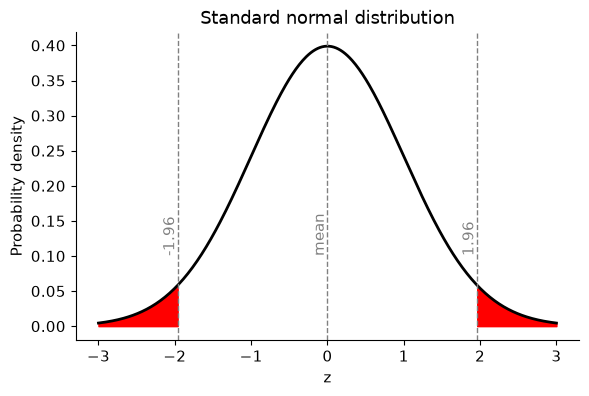

In [47]:
z = np.linspace(-3, 3, 400)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(z, stats.norm.pdf(z), color="black", lw=2)
ax.fill_between(z[z<-1.96], stats.norm.pdf(z[z<-1.96]), color='red')
ax.fill_between(z[z>1.96], stats.norm.pdf(z[z>1.96]), color='red')
for value, name in [(-1.96, "-1.96"), (0, "mean"), (1.96, "1.96")]:
    ax.axvline(value, color="gray", ls="--", lw=1)
    ax.text(value, 0.1, name, rotation=90, ha="right", va="bottom", color="gray")
ax.set_title("Standard normal distribution")
ax.set_xlabel("z")
ax.set_ylabel("Probability density")
plt.show()

$$\text{95\% CI} = \bar{x} \pm 1.96 \cdot SEM$$

(For small samples the t-distribution is used instead of z. This is a topic of the next session.)

**Experiment:** we pretend that the 416 participants are our *population*, so we know the "true" mean of `nWBV`. We draw a random sample of 30 participants and compute the confidence interval.

In [38]:
nwbv = df["nWBV"].to_numpy()
true_mean = nwbv.mean()
z95 = stats.norm.ppf(0.975)

sample = rng.choice(nwbv, size=30, replace=False)
m, sem = sample.mean(), sample.std(ddof=1) / np.sqrt(len(sample))

print(f"'true' population mean: {true_mean:.4f}")
print(f"sample mean = {m:.4f}, SEM = {sem:.4f}")
print(f"95% CI: [{m - z95 * sem:.4f}, {m + z95 * sem:.4f}]  -> contains the true mean: {m - z95 * sem <= true_mean <= m + z95 * sem}")

'true' population mean: 0.7893
sample mean = 0.7833, SEM = 0.0111
95% CI: [0.7615, 0.8052]  -> contains the true mean: True


A single interval can miss the true mean. 95% means: if we repeat the whole procedure many times, about 95% of the intervals contain the true mean. Here are 50 random samples:

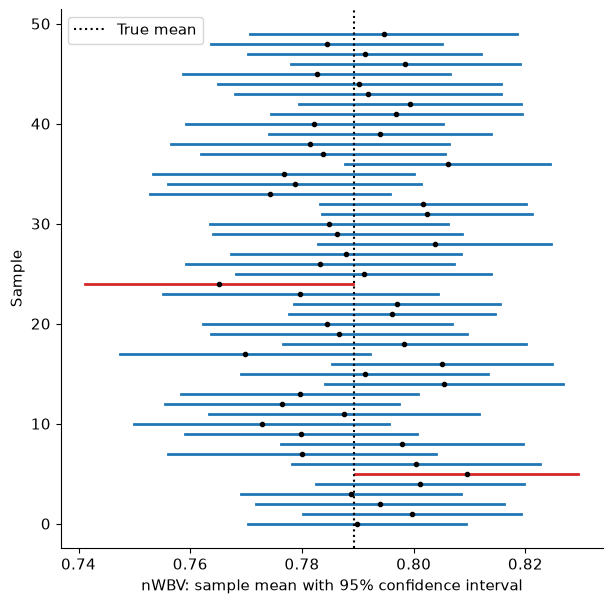

48 of 50 intervals contain the true mean (red = missed it)


In [40]:
n_draws, n = 50, 30
samples = np.array([rng.choice(nwbv, size=n, replace=False) for _ in range(n_draws)])
means = samples.mean(axis=1)
sems = samples.std(axis=1, ddof=1) / np.sqrt(n)
hit = (means - z95 * sems <= true_mean) & (true_mean <= means + z95 * sems)

fig, ax = plt.subplots(figsize=(7, 7))
for i in range(n_draws):
    ax.plot([means[i] - z95 * sems[i], means[i] + z95 * sems[i]], [i, i],
            color="tab:blue" if hit[i] else "tab:red", lw=2)
    ax.plot(means[i], i, "o", color="black", ms=3)
ax.axvline(true_mean, color="black", ls=":", label="True mean")
ax.set_xlabel("nWBV: sample mean with 95% confidence interval")
ax.set_ylabel("Sample")
ax.legend()
plt.show()

print(f"{hit.sum()} of {n_draws} intervals contain the true mean (red = missed it)")

With many more samples, the share of intervals that contain the true mean should be close to 95%:

In [41]:
n_draws = 10_000
samples = np.array([rng.choice(nwbv, size=n, replace=False) for _ in range(n_draws)])
means = samples.mean(axis=1)
sems = samples.std(axis=1, ddof=1) / np.sqrt(n)

coverage = ((means - z95 * sems <= true_mean) & (true_mean <= means + z95 * sems)).mean()
print(f"share of 95% intervals containing the true mean: {coverage:.3f}")

share of 95% intervals containing the true mean: 0.949


### A sample that is not representative

What if the sample is **not random**? Suppose we only recruit participants younger than 30 (138 of the 416). Their brains are, on average, larger than those of the whole group, and the sample means no longer scatter around the true mean:

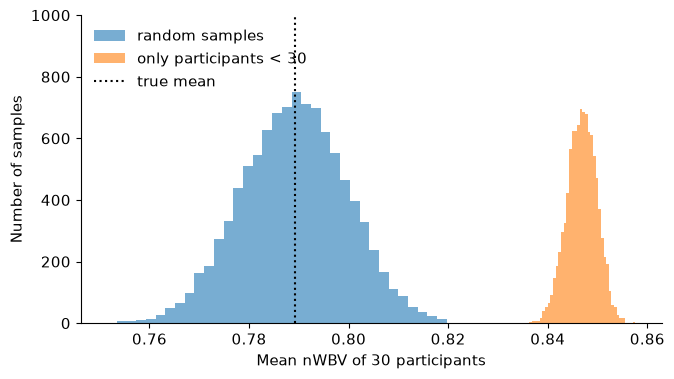

random samples:      95% intervals contain the true mean in 94.9% of the cases
samples of the young: 95% intervals contain the true mean in 0.0% of the cases


In [42]:
young = df.loc[df["Age"] < 30, "nWBV"].to_numpy()

samples_young = np.array([rng.choice(young, size=n, replace=False) for _ in range(n_draws)])
means_young = samples_young.mean(axis=1)
sems_young = samples_young.std(axis=1, ddof=1) / np.sqrt(n)
coverage_young = ((means_young - z95 * sems_young <= true_mean) & (true_mean <= means_young + z95 * sems_young)).mean()

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(means, bins=40, alpha=0.6, label="random samples")
ax.hist(means_young, bins=40, alpha=0.6, label="only participants < 30")
ax.axvline(true_mean, color="black", ls=":", label="true mean")
ax.set_xlabel(f"Mean nWBV of {n} participants")
ax.set_ylabel("Number of samples")
ax.set_ylim(0, 1000)
ax.legend(frameon=False, loc="upper left")
plt.show()

print(f"random samples:      95% intervals contain the true mean in {100 * coverage:.1f}% of the cases")
print(f"samples of the young: 95% intervals contain the true mean in {100 * coverage_young:.1f}% of the cases")

The standard error only describes the *random* variation between samples. It cannot repair a sample that is systematically different from the population. Hence: **sample randomly**.

---
## Summary

| Topic | Key point |
|---|---|
| probability | between 0 and 1; estimated by the relative frequency (law of large numbers) |
| conditional probability | $p(A\|B) = p(A \cap B) / p(B)$; not the same as $p(B\|A)$ |
| addition / multiplication rule | "or" adds (minus the overlap), "and" multiplies (with the conditional probability if dependent) |
| Bayes' theorem | links $p(A\|B)$ and $p(B\|A)$; the base rate matters |
| percentage increases | always name the base rate, prefer percentage points |
| binomial distribution | $k$ successes in a fixed number of trials $n$ |
| Poisson distribution | $k$ events in a fixed interval, mean = variance = $\lambda$ |
| normal distribution | symmetric bell shape; described by mean and SD; assumed by parametric tests |
| z-standardization | $z = (x - \mu)/\sigma$, norm tables give the area to the left |
| sampling | sample randomly; SEM and confidence interval quantify how well the sample mean represents the population mean |

**Source**
- Marcus, D. S. et al. (2007). Open Access Series of Imaging Studies (OASIS): Cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. *Journal of Cognitive Neuroscience, 19*, 1498-1507.